# Loading a cosmological simulation

A quickstart guide to loading the simulation

In [38]:
import yt
import unyt
from astropy.table import Table
import helper_functions as hf
import numpy as np
import matplotlib.pyplot as plt
import se_functions
import importlib

importlib.reload(se_functions)
from se_functions import find_bursts

In [2]:
final_output=116

# Load the timeseries of the most massive black hole

In [3]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

In [4]:
# Load position from file and count BH
filename=f'{df}/output_{str(final_output).zfill(5)}/sink_{str(final_output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")
most_massive_id=t['sink_id'][np.argmax(t['BHmass'])]
print("The most massive BH has id",most_massive_id)

This output contains 684 black holes
The most massive BH has id 5


# Plot evolution of most massive BH

In [5]:
# Load timeseries for most massive black hole
ts=hf.SinkDataLoader(df,sinkid=most_massive_id)

for c in ts.data.colnames:
    print(c, ts.data[c].unit, ts.data[c].shape)

nstep None (137040,)
aexp None (137040,)
time Gyr (137040,)
BHmass solMass (137040,)
position pc (137040, 3)
vsink km / s (137040, 3)
dotMbondi solMass / yr (137040,)
dotMedd solMass / yr (137040,)
rg_scale pc (137040,)
spinmag None (137040,)
dMgrowth solMass (137040,)
dMaccr solMass (137040,)
Esave erg (137040,)
bhspin None (137040, 3)
jsink None (137040, 3)
Efeed erg (137040,)
f_edd None (137040,)
eps_sink None (137040,)
eta_disk None (137040,)
eta_jet None (137040,)
Mass_loading_factor None (137040,)
Rb pc (137040,)
Ra pc (137040,)
Rbhl pc (137040,)
Rbhl_cell pc (137040,)
Ra_cell pc (137040,)
Rb_cell pc (137040,)
dtnew yr (137040,)
dotMgrowth solMass / yr (137040,)
dotMaccr solMass / yr (137040,)
Efeed_Th erg (137040,)
Efeed_Ki erg (137040,)
alpha_madau None (137040,)
beta_eff None (137040,)
z None (137040,)


In [6]:
time=Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt',format='ascii')

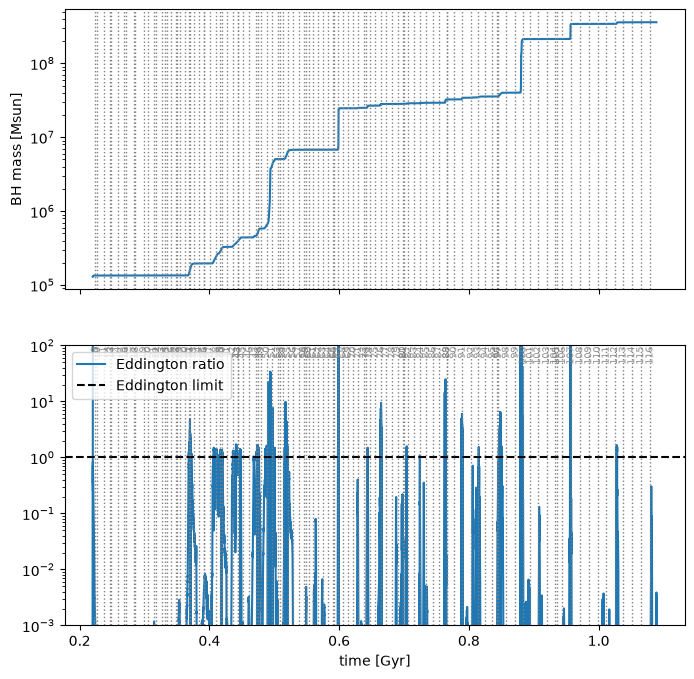

In [7]:
# Full timeseries
fig,axes=plt.subplots(2,1,figsize=(8,8),sharex=True)

# Time window to display (Gyr)
# Edit these values to change the plotted time range
tmin=ts.data['time'][0]  # Start time (Gyr)
tmax=ts.data['time'][-1]  # End time (Gyr)

#tmin = 0.365 #Comment out for whole timeseries
#tmax = 0.38  # Comment out for whole timeseries

# Plot mass (only inside [tmin,tmax])
ax = axes[0]
times = ts.data['time']
mask = (times >= tmin) & (times <= tmax)
ax.plot(times[mask], ts.data['BHmass'][mask], label='BH mass')
ax.set_yscale('log')
ax.set_ylabel('BH mass [Msun]')

# Plot Eddington ratios (only inside [tmin,tmax])
ax = axes[1]
ratio = ts.data['dotMaccr']/ts.data['dotMedd']
ax.plot(times[mask], ratio[mask], label='Eddington ratio')
ax.axhline(1.0, ls='--', color='k', label='Eddington limit')
ax.set_yscale('log')
ax.legend()

# Add output times and redshifts
axes[-1].set_xlabel('time [Gyr]')

# Draw vertical dotted grey lines at each output time from the `time` table (ensure units are Gyr)
try:
    # If `time` is an astropy Table with a column 'time' that may have units
    output_times = time['time']
    # If entries are yt or unyt quantities, convert to float in Gyr
    try:
        output_times_gyr = [t.to('Gyr').v if hasattr(t,'to') else float(t) for t in output_times]
    except Exception:
        # Fallback: assume column already in Gyr or plain numbers
        output_times_gyr = [float(t) for t in output_times]

    # Assume the table has an `output` column containing integer output numbers
    outputs = [int(o) for o in time['output']]
    outputs_labels = [str(o) for o in outputs]
    axes[-1].set_ylim([1e-3,1e2])

    # Draw lines and small grey rotated labels aligned with the vertical lines
    ymin0, ymax0 = axes[0].get_ylim()
    ymin1, ymax1 = axes[1].get_ylim()
    # place labels near the top of the lower subplot (axes[1])
    label_y = ymax1 * 0.95

    # Only show output lines/labels that fall inside [tmin, tmax]
    visible = [(ot, lbl) for ot, lbl in zip(output_times_gyr, outputs_labels) if (ot >= tmin and ot <= tmax)]
    for ot, lbl in visible:
        axes[0].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].text(ot, label_y, lbl, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)
except Exception as e:
    print('Could not draw output-time vertical lines and labels:', e)

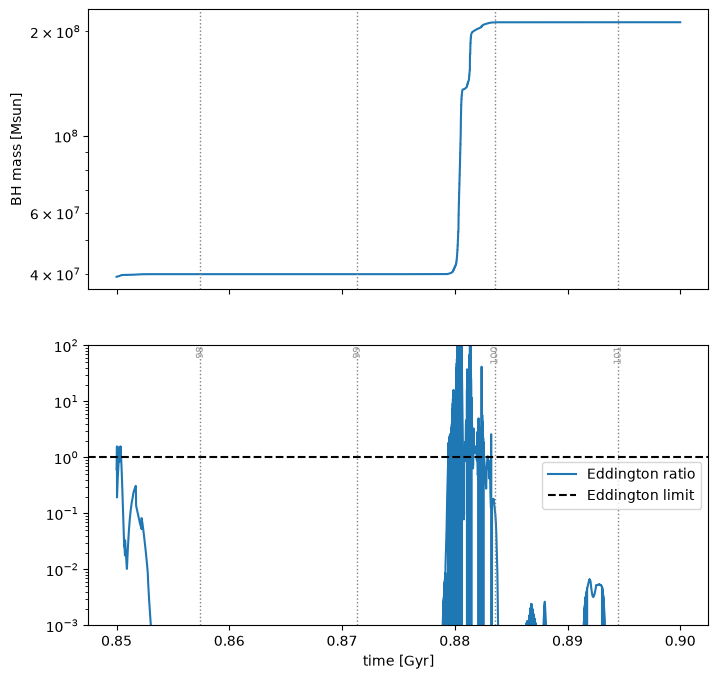

In [8]:
# Full timeseries
fig,axes=plt.subplots(2,1,figsize=(8,8),sharex=True)

# Time window to display (Gyr)
# Edit these values to change the plotted time range
tmin=ts.data['time'][0]  # Start time (Gyr)
tmax=ts.data['time'][-1]  # End time (Gyr)

tmin = 0.85 #Comment out for whole timeseries
tmax = 0.90  # Comment out for whole timeseries

# Plot mass (only inside [tmin,tmax])
ax = axes[0]
times = ts.data['time']
mask = (times >= tmin) & (times <= tmax)
ax.plot(times[mask], ts.data['BHmass'][mask], label='BH mass')
ax.set_yscale('log')
ax.set_ylabel('BH mass [Msun]')

# Plot Eddington ratios (only inside [tmin,tmax])
ax = axes[1]
ratio = ts.data['dotMaccr']/ts.data['dotMedd']
ax.plot(times[mask], ratio[mask], label='Eddington ratio')
ax.axhline(1.0, ls='--', color='k', label='Eddington limit')
ax.set_yscale('log')
ax.legend()

# Add output times and redshifts
axes[-1].set_xlabel('time [Gyr]')

# Draw vertical dotted grey lines at each output time from the `time` table (ensure units are Gyr)
try:
    # If `time` is an astropy Table with a column 'time' that may have units
    output_times = time['time']
    # If entries are yt or unyt quantities, convert to float in Gyr
    try:
        output_times_gyr = [t.to('Gyr').v if hasattr(t,'to') else float(t) for t in output_times]
    except Exception:
        # Fallback: assume column already in Gyr or plain numbers
        output_times_gyr = [float(t) for t in output_times]

    # Assume the table has an `output` column containing integer output numbers
    outputs = [int(o) for o in time['output']]
    outputs_labels = [str(o) for o in outputs]
    axes[-1].set_ylim([1e-3,1e2])

    # Draw lines and small grey rotated labels aligned with the vertical lines
    ymin0, ymax0 = axes[0].get_ylim()
    ymin1, ymax1 = axes[1].get_ylim()
    # place labels near the top of the lower subplot (axes[1])
    label_y = ymax1 * 0.95

    # Only show output lines/labels that fall inside [tmin, tmax]
    visible = [(ot, lbl) for ot, lbl in zip(output_times_gyr, outputs_labels) if (ot >= tmin and ot <= tmax)]
    for ot, lbl in visible:
        axes[0].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].text(ot, label_y, lbl, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)
except Exception as e:
    print('Could not draw output-time vertical lines and labels:', e)

# Generate super-Eddington Catalogue

In [39]:
b = find_bursts(ts.data, gap_myr=0.1)
print(len(b))
b.sort('dM_accr', reverse=True)
b[:10]

29


i_start,i_end,t_start_myr,t_end_myr,duration_myr,aexp_start,aexp_end,M_start,dM_accr,f_edd_max,dM_edd_max
int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
117487,117584,956.0860413212562,956.7077190206932,0.6216776994369866,0.144971603481973,0.145034584244668,214759362.769388,127506721.62853144,3.83838606356281,649.5513805357821
104913,105137,879.4224635152748,880.7104377432252,1.2879742279503716,0.13709835876331,0.137232446046572,40061966.8857575,102072459.63238265,3.67333976063487,352.1526323407555
105173,105310,880.9090989668093,881.6957289744914,0.7866300076821062,0.137253122363752,0.137334978437087,136828518.943607,67804349.01469919,3.79799344535509,546.1231753314818
47654,47925,598.2585171743991,599.345849576729,1.0873324023299347,0.106008901587878,0.106137425404341,6803587.42468251,18544084.022700228,3.6979143973799,379.1260881593993
105419,105459,882.3143342596935,882.5321592318293,0.2178249721357588,0.137399333163693,0.137421990399809,205443678.545633,3687026.6223202897,2.72608566119658,41.78784786285182
26405,26851,490.259899491131,494.18032043814975,3.9204209470187266,0.092823508036094,0.093318001318025,687787.906619867,3171463.916788695,2.63166456419417,33.92864688244531
85327,85390,763.5101696174208,763.9140908144674,0.40392119704654306,0.124750218280854,0.124794276646057,29408256.7441269,2338738.203350717,2.49271947817475,24.836162153428482
117615,117633,956.9049570312785,957.026804663174,0.12184763189543446,0.145054563183066,0.145066904888958,336006564.791875,2084951.0733370392,1.05486429053964,1.6695858861601434
105333,105365,881.8280165207647,881.9995072169905,0.17149069622587376,0.137348741816264,0.137366582936951,201821613.636362,1790475.666559244,1.38099627038601,2.830825677592344


Text(0, 0.5, 'f_edd')

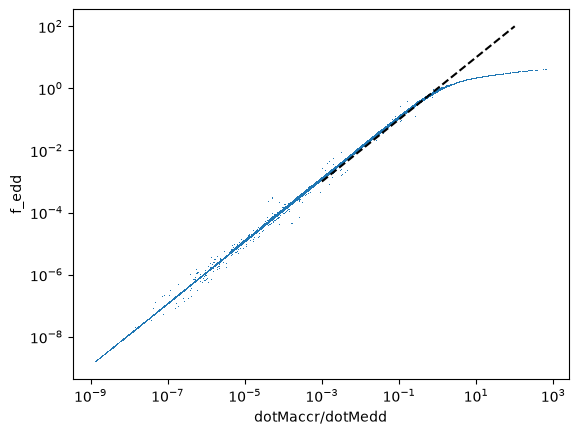

In [26]:
ratio = ts.data['dotMaccr'] / ts.data['dotMedd']
m = ratio > 0
plt.loglog(ratio[m], ts.data['f_edd'][m], ',')
plt.plot([1e-3, 1e2], [1e-3, 1e2], 'k--')
plt.xlabel('dotMaccr/dotMedd')
plt.ylabel('f_edd')

# Load a dataset

In [ ]:
output=99

In [ ]:
ds=yt.load(hf.info_file(output,df))

print(ds.field_list)
print(ds.particle_types)
print(ds.particle_types_raw)

print(ds.parameters['levelmax'])
# print(ds.index.get_smallest_dx().in_units('pc'))
# print(ds.index.get_smallest_dx().in_units('pccm'))

In [ ]:
ad=ds.all_data() # Load a data object that contains all data

print(np.unique(ad['DM', 'particle_mass'].to('Msun')))

In [ ]:
print("The current redshift is",ds.current_redshift) #Load some information on the output

In [ ]:
print("The whole box has a size of",ds.length_unit.in_units('Mpc'))

# Plot the whole box and annotate black holes

In [ ]:
p=yt.ProjectionPlot(ds,normal='z',fields=['density'])
p.annotate_particles(width=ds.length_unit,ptype='sink')
p.show()

# Plot central 1 Mpc and annotate BH

In [ ]:
width=ds.quan(1,'Mpc')  #Width of your plot
region=ds.sphere(ds.arr([0.5,0.5,0.5],'code_length'),width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region)
p.annotate_particles(width=width*2,ptype='cloud',data_source=region,p_size=15)
p.show()

# Center plot on sink number 5

In [ ]:
target_sink=5

In [ ]:
# Load position from file at this output
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

In [ ]:
# Find position of target BH
sink_pos=t[t['sink_id']==target_sink]['x','y','z'] # Position on 6th sink
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length') #Position converted to something the dataset understands by adding units and stripping formatting

In [ ]:
# Make plot centred on BH 17, zooming in to the central 300 kpc
width=ds.quan(300,'kpc')  #Width of your plot
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region,center=sink_pos_ds)
p.annotate_particles(width=width.in_units('code_length'),ptype='cloud',data_source=region,p_size=15)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

p.show()

In [ ]:
# Make plot centred on BH 17, zooming in to the central 10 kpc
width = ds.quan(10, 'kpc')  # Width of your plot
region = ds.sphere(sink_pos_ds, width)  # Make a sphere with the data you want to plot
p = yt.ProjectionPlot(ds, normal='z', fields=['density'], width=width, data_source=region, center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)
p.set_zlim(('gas','density'), 1e-3, 5)

p.save(f'fig/density_density_{output:03d}.png')
p.show()

In [ ]:
# Plot temperature instead, reusing the data objects
width=ds.quan(10,'kpc')
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['temperature'], weight_field=('gas','density'),
width=width,data_source=region,center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)
p.set_cmap('temperature', 'plasma')
p.set_zlim('temperature', 1e3, 3e7)

p.save(f'fig/tem_density_{output:03d}.png')
p.show()

In [ ]:
sp = ds.sphere(sink_pos_ds, (5, 'kpc'))
E_th = (1.5 * sp['gas','pressure'] * sp['gas','cell_volume']).sum().to('erg')
print(E_th)

# 6.786206708326559e+56 erg for snapshot 099
# 7.676195514036063e+57 erg for snapshot 100

In [ ]:
# Plot stellar distribution instead, reusing the data objects
field=('deposit','star_cic')
p = yt.ProjectionPlot(ds, normal='z', fields=[field],
                      width=width, data_source=region, 
                      center=sink_pos_ds,weight_field=field)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

# Use inferno colormap for the stellar field
p.set_cmap(field, 'inferno')

p.show()

# Measure gas properties within 1 kpc of sink 

In [ ]:
sp=ds.sphere(sink_pos_ds,ds.quan(2,'kpc')) # Make a sphere with the data you want to plot
print("Maximum density within 2 kpc of sink 6:",sp['density'].max().in_units('g/cm**3'))
print("Maximum temperature within 2 kpc of sink 6:",sp['temperature'].max())
print("Total gas mass within 2 kpc of the sink",sp['mass'].sum().in_units('Msun'))

In [ ]:
print("Maximum stellar mass in this sphere is",sp['star','particle_mass'].in_units('Msun').max())

In [ ]:
# Make plot centred on BH 17, zooming in to the central 10 kpc
width=ds.quan(10,'kpc')  #Width of your plot
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region,center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

# Annotate the sphere `sp` using yt's native annotation (handles coordinates/radius)
# Draw an unfilled red circle corresponding to the sphere projection
# pass styling via `circle_args` dict
p.annotate_sphere(sp.center, sp.radius, coord_system='data', circle_args={'color': 'red',  'linewidth': 2})

p.show()